In [ ]:
import geopandas as gpd

data_dir = "/Users/shouryakulkarni/IDX-Exchange-Data-Science"
districts = gpd.read_file(f"{data_dir}/data/DistrictAreas2425/DistrictAreas2425.shp")

print(districts.shape)   # (number of districts, number of columns)
print(districts.crs)     # the coordinate system
districts.head()

Note: you may need to restart the kernel to use updated packages.
(937, 54)
EPSG:3857


,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictNa,DistrictTy,GradeLow,GradeHigh,...,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAre,Shape__Are,Shape__Len,geometry
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683,"MULTIPOLYGON (((-13606222.82 4540862.699, -136..."
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797,"POLYGON ((-13612893.866 4565099.707, -13612896..."
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538,"POLYGON ((-13609482.48 4565074.597, -13609483...."
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565,"MULTIPOLYGON (((-13582508.535 4529067.071, -13..."
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894,"POLYGON ((-13613999.038 4555592.769, -13614126..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

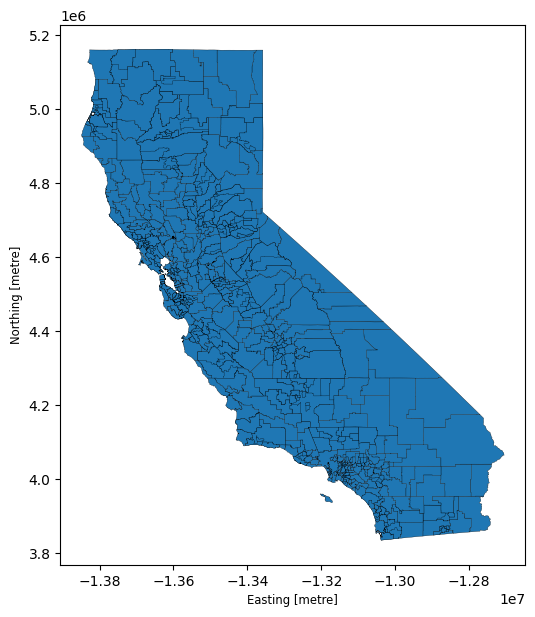

In [26]:
districts.plot(figsize=(6, 8), edgecolor="black", linewidth=0.2)

In [27]:
print("Coordinate system:", districts.crs)
print("\nColumns:", list(districts.columns))

# Show any column with only a few distinct values (likely the district TYPE column)
for col in districts.columns:
    if col != "geometry" and districts[col].nunique() <= 10:
        print(f"\n{col}:")
        print(districts[col].value_counts())

districts.drop(columns="geometry").head()

Coordinate system: EPSG:3857

Columns: ['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictNa', 'DistrictTy', 'GradeLow', 'GradeHigh', 'GradeLowCe', 'GradeHighC', 'AssistStat', 'CongressUS', 'SenateCA', 'AssemblyCA', 'UpdateNote', 'EnrollTota', 'EnrollChar', 'EnrollNonC', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAre', 'Shape__Are', 'Shape__Len', 'geometry']

Year:
Year
2024-25    937
Name: count, dtype: int64

DistrictTy:
DistrictTy
Elementary    516
Unified       345
High           76
Name: count, dtype: int64

GradeLow:
GradeLow
KG    474
PK    399
09     51
07      5
06      4
08      2
05      2
Name: count, dtype: int64

GradeHigh:
GradeHigh
12    483
08    410
06     40
05      4
Name: 

,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictNa,DistrictTy,GradeLow,GradeHigh,...,HOMpct,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAre,Shape__Are,Shape__Len
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0.7,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0.6,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,2.1,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,1.3,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,2.5,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894


In [28]:
import pandas as pd
import numpy as np

clean = pd.read_csv(f"{data_dir}/cleaned_sfr.csv",
                    dtype={"PostalCode": str}, parse_dates=["CloseDate"])
print("Homes missing coordinates:", clean["Latitude"].isna().sum())

Homes missing coordinates: 212


In [30]:
# 1. Longitude sign flipped (California longitudes are always negative)
flip = clean["Longitude"].between(114, 125)
clean.loc[flip, "Longitude"] *= -1
print("Longitudes sign-flipped back:", flip.sum())

# 2. Coordinates outside California's bounding box -> missing
outside_ca = ~(clean["Latitude"].between(32.4, 42.1) & clean["Longitude"].between(-124.5, -114.1))
bad_coords = outside_ca & clean["Latitude"].notna()
clean.loc[bad_coords, ["Latitude", "Longitude"]] = np.nan
print("Impossible coordinates set to missing:", bad_coords.sum())

Longitudes sign-flipped back: 11
Impossible coordinates set to missing: 14


In [34]:
homes = gpd.GeoDataFrame(
    clean[["Latitude", "Longitude"]],
    geometry=gpd.points_from_xy(clean["Longitude"], clean["Latitude"]),
    crs="EPSG:4326",
)
districts_ll = districts.to_crs("EPSG:4326")
print(f"{len(homes):,} homes, {len(districts_ll):,} districts")

107,416 homes, 937 districts


In [35]:
def match_district(types, label, max_m=1000):
    d = districts_ll[districts_ll["DistrictTy"].isin(types)][["CDSCode", "DistrictNa", "CountyName", "geometry"]]
    joined = gpd.sjoin(homes[["geometry"]], d, how="left", predicate="within")
    dupes = joined.index.duplicated(keep="first")
    joined = joined[~dupes]

    # Fallback: valid coordinates but just outside every boundary (e.g., shoreline)
    miss = joined["CDSCode"].isna() & clean["Latitude"].notna()
    if miss.any():
        near = gpd.sjoin_nearest(homes.loc[miss, ["geometry"]].to_crs(3310),
                                 d.to_crs(3310), how="left", max_distance=max_m)
        near = near[~near.index.duplicated(keep="first")].dropna(subset=["CDSCode"])
        joined.loc[near.index, ["CDSCode", "DistrictNa", "CountyName"]] = near[["CDSCode", "DistrictNa", "CountyName"]]
    else:
        near = []

    print(f"{label}: {dupes.sum()} boundary duplicates (kept first), "
          f"{len(near)} matched to nearest district within {max_m} m")
    return joined["CDSCode"], joined["DistrictNa"], joined["CountyName"]

clean["ElemDistrict"], clean["ElemDistrictName"], elem_county = match_district(["Unified", "Elementary"], "Elementary")
clean["HighDistrict"], clean["HighDistrictName"], _ = match_district(["Unified", "High"], "High school")

for col in ["ElemDistrict", "HighDistrict"]:
    print(f"{col}: {clean[col].notna().mean():.1%} of homes matched, {clean[col].nunique()} districts")

Elementary: 483 boundary duplicates (kept first), 8 matched to nearest district within 1000 m
High school: 0 boundary duplicates (kept first), 81 matched to nearest district within 1000 m
ElemDistrict: 99.8% of homes matched, 669 districts
HighDistrict: 99.8% of homes matched, 393 districts


In [36]:
check = pd.DataFrame({"listing_county": clean.loc[flip, "CountyOrParish"],
                      "district_county": elem_county[flip],
                      "district": clean.loc[flip, "ElemDistrictName"]})
check["same_county"] = check["listing_county"] == check["district_county"]
print(f"Flipped homes in the county their listing says: {check['same_county'].mean():.0%}")
check.head(10)

Flipped homes in the county their listing says: 91%


,listing_county,district_county,district,same_county
18980,Los Angeles,Los Angeles,Palos Verdes Peninsula Unified,True
25052,Tulare,Tulare,Pixley Union Elementary,True
28052,Fresno,Fresno,Clovis Unified,True
48811,Santa Barbara,Santa Barbara,Santa Maria-Bonita,True
49318,Riverside,Riverside,Moreno Valley Unified,True
49998,Riverside,Riverside,Lake Elsinore Unified,True
53354,Los Angeles,Los Angeles,El Rancho Unified,True
70479,San Bernardino,San Bernardino,Hesperia Unified,True
79769,Los Angeles,Kern,South Fork Union,False
98617,Riverside,Riverside,Alvord Unified,True


In [37]:
unmatched = clean[clean["ElemDistrict"].isna()]
print(f"{len(unmatched):,} homes with no elementary/unified district")
unmatched[["City", "CountyOrParish", "Latitude", "Longitude"]].head(10)

226 homes with no elementary/unified district


,City,CountyOrParish,Latitude,Longitude
3886,Carmel,Monterey,NaN,NaN
6653,Los Gatos,Santa Clara,NaN,NaN
21145,Mountain House,San Joaquin,NaN,NaN
32373,Salinas,Monterey,NaN,NaN
41991,Carmel,Monterey,NaN,NaN
44121,Palmdale,Los Angeles,NaN,NaN
46701,Carmel,Monterey,NaN,NaN
57659,Marina,Monterey,NaN,NaN
58383,Palmdale,Los Angeles,NaN,NaN
61441,Carmel,Monterey,NaN,NaN


In [38]:
mismatch = flip & (elem_county != clean["CountyOrParish"])
cols = ["Latitude", "Longitude", "ElemDistrict", "ElemDistrictName", "HighDistrict", "HighDistrictName"]
clean.loc[mismatch, cols] = np.nan
print("Flipped homes in the wrong county, set to unknown:", mismatch.sum())

Flipped homes in the wrong county, set to unknown: 1


In [39]:
clean["PropertyAge"] = (clean["CloseDate"].dt.year - clean["YearBuilt"]).clip(lower=0)
clean["BedBathRatio"] = clean["BedroomsTotal"] / clean["BathroomsTotalInteger"]
clean[["PropertyAge", "BedBathRatio"]].describe().round(2)

,PropertyAge,BedBathRatio
count,107360.00,107357.00
mean,49.51,1.46
std,27.58,0.47
min,0.00,0.14
25%,27.00,1.00
50%,49.00,1.50
75%,70.00,1.50
max,172.00,7.50


In [40]:
clean.to_csv(f"{data_dir}/data/cleaned_sfr_districts.csv", index=False)
print("Saved", clean.shape)

Saved (107416, 26)


In [41]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, TargetEncoder,
                                   FunctionTransformer)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

random_state = 42
best_x = 7
target = "ClosePrice"

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=18, min_samples_leaf=20,
                                           random_state=random_state),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                           max_features=0.6, n_jobs=-1,
                                           random_state=random_state),
}

In [42]:
skewed_features = ["LivingArea", "LotSqFt"]
base_numeric = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSqFt",
                "YearBuilt", "Latitude", "Longitude", "GarageSpaces", "Stories"]
binary_features = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]
low_card_categorical = ["CountyOrParish"]
base_high = ["City", "PostalCode"]

new_numeric = ["PropertyAge", "BedBathRatio"]
new_high = ["ElemDistrict", "HighDistrict"]

feature_sets = {
    "Week 5 (old)":       {"numeric": base_numeric,               "high": base_high},
    "+ age & bed/bath":   {"numeric": base_numeric + new_numeric, "high": base_high},
    "+ school districts": {"numeric": base_numeric,               "high": base_high + new_high},
    "All new features":   {"numeric": base_numeric + new_numeric, "high": base_high + new_high},
}

In [44]:
def fit_outlier_bounds(train, lo=0.005, hi=0.995):
    ppsf = train[target] / train["LivingArea"]
    return {"price_lo": train[target].quantile(lo), "price_hi": train[target].quantile(hi),
            "ppsf_lo": ppsf.quantile(lo), "ppsf_hi": ppsf.quantile(hi)}

def apply_outlier_bounds(data, b):
    ppsf = data[target] / data["LivingArea"]
    keep = (data[target].between(b["price_lo"], b["price_hi"]) &
            ppsf.between(b["ppsf_lo"], b["ppsf_hi"]))
    return data[keep]

def make_preprocessor(numeric, high):
    skewed = [c for c in numeric if c in skewed_features]
    other = [c for c in numeric if c not in skewed_features]
    skewed_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    low_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ])
    high_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("target", TargetEncoder(target_type="continuous", random_state=random_state)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("skew", skewed_pipe, skewed),
        ("num", numeric_pipe, other),
        ("bin", "passthrough", binary_features),
        ("low", low_pipe, low_card_categorical),
        ("high", high_pipe, high),
    ])

def evaluate(y_true, y_pred):
    pct_err = np.abs(y_pred - y_true) / y_true
    return {"R2": r2_score(y_true, y_pred),
            "MAPE %": pct_err.mean() * 100,
            "MdAPE %": np.median(pct_err) * 100,
            "MAE $": mean_absolute_error(y_true, y_pred),
            "Within 20 %": (pct_err <= 0.20).mean() * 100}

def fit_and_score(estimator, train, eval_set, fs):
    feats = fs["numeric"] + binary_features + low_card_categorical + fs["high"]
    b = fit_outlier_bounds(train)
    tr, ev = apply_outlier_bounds(train, b), apply_outlier_bounds(eval_set, b)
    model = Pipeline([("prep", make_preprocessor(fs["numeric"], fs["high"])),
                      ("model", clone(estimator))])
    model.fit(tr[feats], np.log(tr[target]))
    pred = np.exp(model.predict(ev[feats]))
    return evaluate(ev[target].values, pred), model, ev, pred

In [45]:
months = sorted(clean["CloseMonth"].unique())
tune_train = clean[clean["CloseMonth"].isin(months[-2 - best_x : -2])]
val = clean[clean["CloseMonth"] == months[-2]]
final_train = clean[clean["CloseMonth"].isin(months[-1 - best_x : -1])]
test = clean[clean["CloseMonth"] == months[-1]]
print("Validate on", months[-2], "| Test on", months[-1])

Validate on 2026-03 | Test on 2026-04


In [46]:
rows, preds = [], {}
for fs_name, fs in feature_sets.items():
    for m_name, est in models.items():
        val_m, _, _, _ = fit_and_score(est, tune_train, val, fs)
        test_m, _, test_f, pred = fit_and_score(est, final_train, test, fs)
        rows.append({"features": fs_name, "model": m_name, "split": "validation (Mar)", **val_m})
        rows.append({"features": fs_name, "model": m_name, "split": "test (Apr)", **test_m})
        preds[(fs_name, m_name)] = pred
        print(f"{fs_name:20s} {m_name:18s} val MdAPE {val_m['MdAPE %']:.2f}%  test MdAPE {test_m['MdAPE %']:.2f}%")

results = pd.DataFrame(rows)

Week 5 (old)         Linear Regression  val MdAPE 11.45%  test MdAPE 11.40%
Week 5 (old)         Decision Tree      val MdAPE 10.29%  test MdAPE 10.50%
Week 5 (old)         Random Forest      val MdAPE 8.28%  test MdAPE 8.39%
+ age & bed/bath     Linear Regression  val MdAPE 11.34%  test MdAPE 11.31%
+ age & bed/bath     Decision Tree      val MdAPE 10.23%  test MdAPE 10.57%
+ age & bed/bath     Random Forest      val MdAPE 8.26%  test MdAPE 8.35%
+ school districts   Linear Regression  val MdAPE 11.29%  test MdAPE 11.38%
+ school districts   Decision Tree      val MdAPE 10.21%  test MdAPE 10.39%
+ school districts   Random Forest      val MdAPE 8.12%  test MdAPE 8.25%
All new features     Linear Regression  val MdAPE 11.22%  test MdAPE 11.26%
All new features     Decision Tree      val MdAPE 10.17%  test MdAPE 10.44%
All new features     Random Forest      val MdAPE 8.13%  test MdAPE 8.28%


In [47]:
summary = (results.pivot_table(index="features", columns=["model", "split"], values="MdAPE %")
                  .reindex(list(feature_sets)).round(2))
summary

model              Decision Tree                  Linear Regression  \
split                 test (Apr) validation (Mar)        test (Apr)   
features                                                              
Week 5 (old)               10.50            10.29             11.40   
+ age & bed/bath           10.57            10.23             11.31   
+ school districts         10.39            10.21             11.38   
All new features           10.44            10.17             11.26   

model                               Random Forest                   
split              validation (Mar)    test (Apr) validation (Mar)  
features                                                            
Week 5 (old)                  11.45          8.39             8.28  
+ age & bed/bath              11.34          8.35             8.26  
+ school districts            11.29          8.25             8.12  
All new features              11.22          8.28             8.13

In [48]:
rf_val = results[(results["model"] == "Random Forest") &
                 (results["split"] == "validation (Mar)")].set_index("features")["MdAPE %"]
best_set = rf_val.idxmin()
print("Best feature set (by Random Forest validation MdAPE):", best_set)

results[results["features"].isin(["Week 5 (old)", best_set]) &
        (results["model"] == "Random Forest")].set_index(["features", "split"]).round(3)

Best feature set (by Random Forest validation MdAPE): + school districts


model     R2  MAPE %  MdAPE %  \
features           split                                                     
Week 5 (old)       validation (Mar)  Random Forest  0.878  11.906    8.281   
                   test (Apr)        Random Forest  0.872  12.160    8.394   
+ school districts validation (Mar)  Random Forest  0.882  11.757    8.123   
                   test (Apr)        Random Forest  0.874  12.065    8.247   

                                          MAE $  Within 20 %  
features           split                                      
Week 5 (old)       validation (Mar)  162578.988       82.665  
                   test (Apr)        170583.005       82.735  
+ school districts validation (Mar)  160228.013       83.123  
                   test (Apr)        168799.019       82.939

In [49]:
bands = pd.qcut(test_f[target], 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
band_rows = []
for fs_name in ["Week 5 (old)", best_set]:
    pred = preds[(fs_name, "Random Forest")]
    pct = (pred - test_f[target].values) / test_f[target].values * 100
    tmp = pd.DataFrame({"band": bands.values, "abs": np.abs(pct), "signed": pct})
    g = tmp.groupby("band", observed=True).agg(MdAPE=("abs", "median"), bias=("signed", "median"))
    g["features"] = fs_name
    band_rows.append(g.reset_index())

band_table = pd.concat(band_rows).pivot(index="band", columns="features", values=["MdAPE", "bias"])
band_table.round(1)

MdAPE                            bias             
features    + school districts Week 5 (old) + school districts Week 5 (old)
band                                                                       
Q1 cheapest                7.2          7.2                1.6          1.6
Q2                         6.2          6.1               -0.7         -0.9
Q3                         7.2          7.2               -1.7         -1.7
Q4                         9.3          9.6               -4.3         -4.3
Q5 priciest               13.4         13.4               -9.1         -9.6

In [50]:
def backtest(estimator, data, X, fs, n_cutoffs=3):
    months = sorted(data["CloseMonth"].unique())
    rows = []
    for tm in months[::-1][:n_cutoffs]:
        t = months.index(tm)
        if t < X:
            print(f"Skipping {tm}: needs {X} prior months, only {t} available")
            continue
        tr = data[data["CloseMonth"].isin(months[t - X:t])]
        te = data[data["CloseMonth"] == tm]
        m, _, _, _ = fit_and_score(estimator, tr, te, fs)
        rows.append({"test month": tm, **m})
    return pd.DataFrame(rows)

bt = pd.concat({name: backtest(models["Random Forest"], clean, best_x, feature_sets[name])
                for name in ["Week 5 (old)", best_set]})
bt[["test month", "R2", "MdAPE %", "Within 20 %"]].round(3)

test month     R2  MdAPE %  Within 20 %
Week 5 (old)       0    2026-04  0.872    8.394       82.735
                   1    2026-03  0.878    8.281       82.665
                   2    2026-02  0.879    8.455       81.440
+ school districts 0    2026-04  0.874    8.247       82.939
                   1    2026-03  0.882    8.123       83.123
                   2    2026-02  0.880    8.374       81.770

In [51]:
old_m = bt.loc["Week 5 (old)"].set_index("test month")["MdAPE %"]
new_m = bt.loc[best_set].set_index("test month")["MdAPE %"]
pd.DataFrame({"old": old_m, "new": new_m, "improvement": old_m - new_m}).round(2)

,old,new,improvement
test month,,,
2026-04,8.39,8.25,0.15
2026-03,8.28,8.12,0.16
2026-02,8.46,8.37,0.08


In [52]:
_, rf_best, _, _ = fit_and_score(models["Random Forest"], final_train, test, feature_sets[best_set])
names = rf_best.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf_best.named_steps["model"].feature_importances_, index=names)
importance.sort_values(ascending=False).head(15).round(3)

high__PostalCode              0.463
skew__LivingArea              0.156
high__City                    0.155
high__ElemDistrict            0.074
high__HighDistrict            0.041
num__BathroomsTotalInteger    0.034
skew__LotSqFt                 0.017
num__Longitude                0.016
num__Latitude                 0.012
num__YearBuilt                0.011
num__BedroomsTotal            0.007
num__GarageSpaces             0.003
bin__PoolPrivateYN            0.001
num__Stories                  0.001
bin__FireplaceYN              0.001
dtype: float64

## Week 6 Findings: Feature Engineering

**New features**
- **School districts:** matched each home's coordinates to the CA School District Areas 2024-25 boundaries (spatial join). Two features: elementary district (unified or elementary) and high school district (unified or high), since elementary and high school districts overlap. 99.8% of homes matched; the unmatched ones have missing coordinates.
- **Property age at sale** and **bed/bath ratio**, from the project doc's examples.
- **Coordinate fixes found along the way:** 11 longitudes with a dropped minus sign (flipped back, and 10 of 11 confirmed by landing in the listed county), 14 impossible coordinates (e.g. 0,0) set to missing, 89 shoreline homes matched to the nearest district within 1 km.

**Old vs. new feature sets (MdAPE; chosen on March, reported on April)**
| Features | LR (Apr) | DT (Apr) | RF (Mar) | RF (Apr) |
|---|---|---|---|---|
| Week 5 (old) | 11.40% | 10.50% | 8.28% | 8.39% |
| + age & bed/bath | 11.31% | 10.57% | 8.26% | 8.35% |
| **+ school districts** | 11.38% | 10.39% | **8.12%** | **8.25%** |
| All new features | 11.26% | 10.44% | 8.13% | 8.28% |

**Result:** school districts give a small but consistent gain. The random forest improved in all 3 backtest months (0.08–0.16 pts), with R² 0.872 → 0.874 and 82.7% → 82.9% within 20% on April. Age and bed/bath ratio added nothing: age repeats year built, and the forest already combines bedrooms and bathrooms. **Adopted "+ school districts" for week 7.**

**Why the gain is small:** the district features rank 4th–5th in importance but mostly overlap with ZIP and City (their importance dropped from 50% to 46% and from 20% to 16%).

**Still unsolved:** the priciest 20% of homes are still underestimated by ~9% (MdAPE 13.4%). Finer location detail didn't fix this, so it likely needs a different model (week 7, gradient boosting) or more luxury sales to learn from.

In [55]:
results.to_csv(f"{data_dir}/feature_comparison.csv", index=False)
print("Saved feature_comparison.csv")

Saved feature_comparison.csv
